# EDA on Retail Sales Data

## OASIS INFOBYTE Data Analytics Internship

### Level 1 — Task 1

This project performs Exploratory Data Analysis (EDA) on a retail sales dataset to identify sales patterns, customer behaviour trends, product performance, and actionable business insights.

### Objectives

- Understand the structure and quality of the retail sales data.
- Analyze descriptive statistics.
- Identify monthly and quarterly sales trends.
- Analyze customer demographics.
- Identify top-performing products and product categories.
- Explore relationships between numerical variables.
- Discover additional business insights through visualization.
- Provide actionable recommendations based on the analysis.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

%matplotlib inline

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load Dataset

The dataset is loaded from the local `data` folder. Keeping the raw dataset inside the project makes the analysis reproducible and keeps the project organized.

In [24]:
df = pd.read_csv("../data/retail_sales_dataset.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [25]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [26]:
df.tail()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150
999,1000,2023-04-12,CUST1000,Male,47,Electronics,4,30,120


## 4. Initial Data Inspection

Before performing the analysis, we inspect the dataset structure, dimensions, data types, and missing values.

In [27]:
print("Column names:")
for column in df.columns:
    print("-", column)
print("\nDataset shape:", df.shape)    
print("\nNumber of rows:", df.shape[0])
print("\nNumber of columns:", df.shape[1]) 
df.shape
df.columns
df.dtypes

print ("\nmissing value in each column :" , df.isnull().sum())
print ("\ntotal number of missing values :" ,df.isnull().sum().sum() )
print("\nDuplicate rows:", df.duplicated().sum())
df.info()


Column names:
- Transaction ID
- Date
- Customer ID
- Gender
- Age
- Product Category
- Quantity
- Price per Unit
- Total Amount

Dataset shape: (1000, 9)

Number of rows: 1000

Number of columns: 9

missing value in each column : Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

total number of missing values : 0

Duplicate rows: 0
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7  

## 5. Descriptive Statistics

Descriptive statistics provide a numerical overview of the dataset. The analysis includes the mean, median, mode, and standard deviation for numerical variables.

In [28]:
numeric_columns = df.select_dtypes(include=np.number).columns

print("Numerical columns:")
print(list(numeric_columns))

df[numeric_columns].describe().T

Numerical columns:
['Transaction ID', 'Age', 'Quantity', 'Price per Unit', 'Total Amount']


,count,mean,std,min,25%,50%,75%,max
Transaction ID,1000.0,500.500,288.819436,1.0,250.75,500.5,750.25,1000.0
Age,1000.0,41.392,13.681430,18.0,29.00,42.0,53.00,64.0
Quantity,1000.0,2.514,1.132734,1.0,1.00,3.0,4.00,4.0
Price per Unit,1000.0,179.890,189.681356,25.0,30.00,50.0,300.00,500.0
Total Amount,1000.0,456.000,559.997632,25.0,60.00,135.0,900.00,2000.0


In [29]:
descriptive_statistics = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Mode": df[numeric_columns].mode().iloc[0],
    "Standard Deviation": df[numeric_columns].std()
})

descriptive_statistics

,Mean,Median,Mode,Standard Deviation
Transaction ID,500.500,500.5,1.0,288.819436
Age,41.392,42.0,43.0,13.681430
Quantity,2.514,3.0,4.0,1.132734
Price per Unit,179.890,50.0,50.0,189.681356
Total Amount,456.000,135.0,50.0,559.997632


##  Data Preparation

The date column is converted to datetime format so that monthly and quarterly sales trends can be analyzed correctly.

In [30]:
# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Date conversion completed.")
print("Date data type:", df["Date"].dtype)

Date conversion completed.
Date data type: datetime64[us]


In [31]:
print("Invalid or missing dates:", df["Date"].isna().sum())

Invalid or missing dates: 0


In [32]:
df["Month"] = df["Date"].dt.to_period("M").astype(str)
df["Quarter"] = df["Date"].dt.to_period("Q").astype(str)

df[["Date", "Month", "Quarter"]].head()

,Date,Month,Quarter
0,2023-11-24,2023-11,2023Q4
1,2023-02-27,2023-02,2023Q1
2,2023-01-13,2023-01,2023Q1
3,2023-05-21,2023-05,2023Q2
4,2023-05-06,2023-05,2023Q2


##  Monthly Sales Trend

Monthly sales are analyzed to identify periods of higher and lower revenue and to understand how sales change over time.

In [33]:
monthly_sales = (
    df.groupby("Month")["Total Amount"]
      .sum()
      .reset_index()
)

monthly_sales.head()

,Month,Total Amount
0,2023-01,35450
1,2023-02,44060
2,2023-03,28990
3,2023-04,33870
4,2023-05,53150


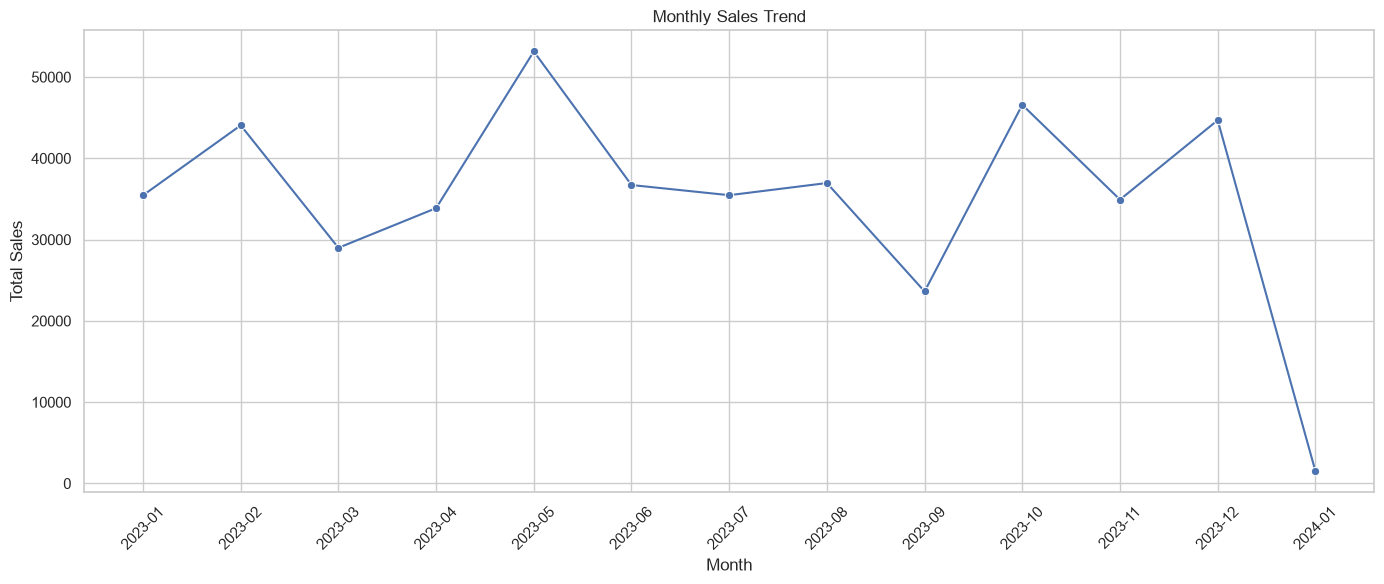

In [34]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Total Amount",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("../images/monthly_sales_trend.png", dpi=300, bbox_inches="tight")

plt.show()

### Observation

Monthly sales show noticeable variation throughout the analysis period. Sales reached their highest level in May 2023 at approximately $53,150, while September recorded the lowest monthly sales in 2023 at approximately $23,620. Sales also increased strongly in October and December after the decline observed in September. Overall, the results indicate that retail demand fluctuates considerably from month to month, which suggests that inventory and promotional planning should take monthly demand patterns into account.

##  Quarterly Sales Trend

Quarterly sales are analyzed to identify broader business trends and determine whether sales performance changes across quarters.

In [35]:
quarterly_sales = (
    df.groupby("Quarter")["Total Amount"]
      .sum()
      .reset_index()
)

quarterly_sales

,Quarter,Total Amount
0,2023Q1,108500
1,2023Q2,123735
2,2023Q3,96045
3,2023Q4,126190
4,2024Q1,1530


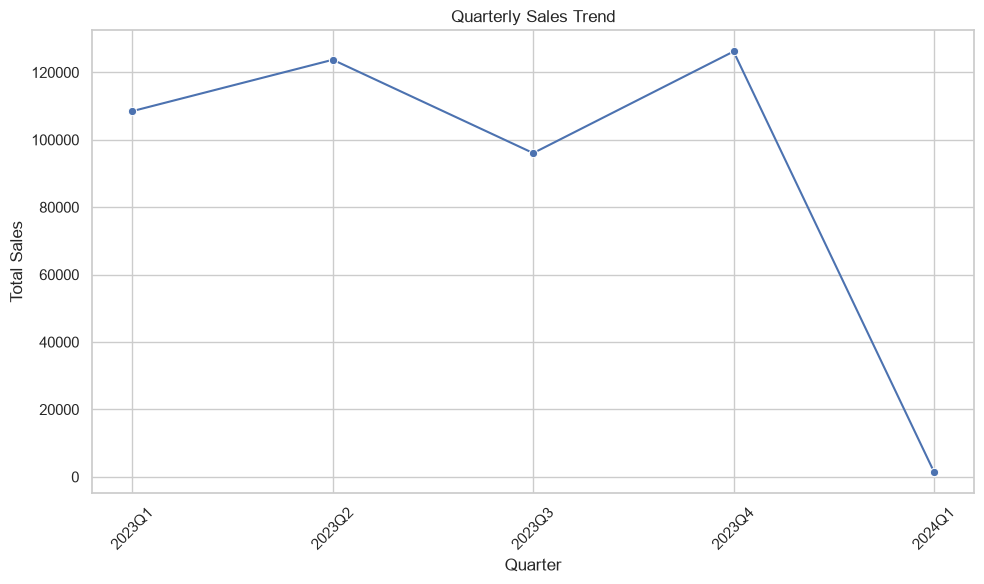

In [36]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=quarterly_sales,
    x="Quarter",
    y="Total Amount",
    marker="o"
)

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("../images/quarterly_sales_trend.png", dpi=300, bbox_inches="tight")

plt.show()

### Observation

Quarterly sales show that the strongest performance occurred in Q4 2023, followed closely by Q2 2023. Q3 2023 recorded the lowest sales among the complete quarters, indicating a noticeable decline in business activity during this period. The small Q1 2024 value represents only a partial period and should not be compared directly with the complete 2023 quarters. Overall, the quarterly analysis suggests that the business experienced stronger performance toward the end of 2023.

## Customer Demographics

Customer demographic analysis helps identify which customer groups contribute to the retail business and whether purchasing behaviour differs across demographic categories.

In [37]:
# Create age groups
bins = [0, 17, 25, 35, 45, 55, 65, 100]
labels = [
    "Under 18",
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56-65",
    "66+"
]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

age_group_counts = df["Age Group"].value_counts().sort_index()

age_group_counts

Age Group
Under 18      0
18-25       169
26-35       205
36-45       202
46-55       229
56-65       195
66+           0
Name: count, dtype: int64

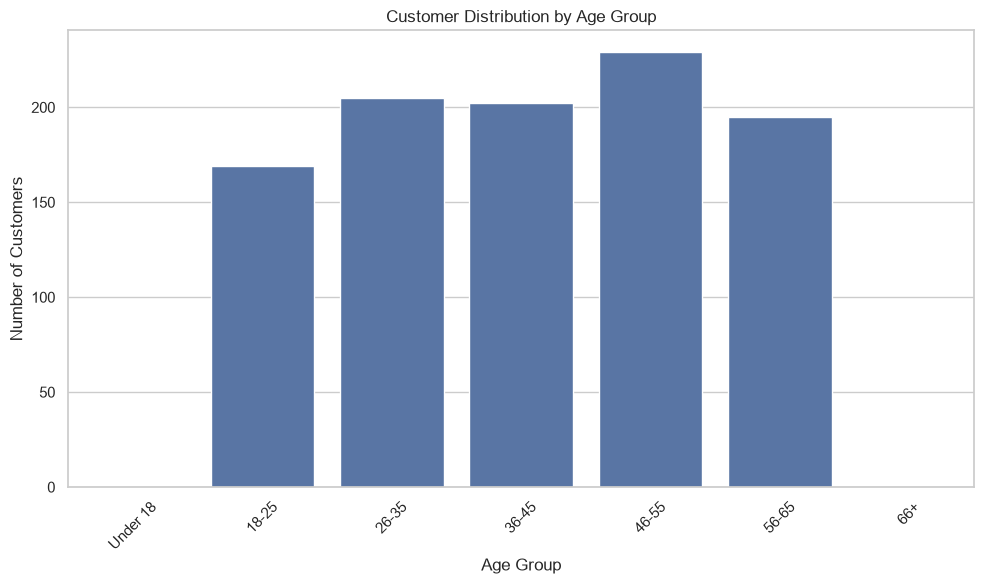

In [38]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=age_group_counts.index,
    y=age_group_counts.values
)

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("../images/customer_age_groups.png", dpi=300, bbox_inches="tight")

plt.show()

### Observation

The customer base is concentrated among customers aged 18 to 65. The 46–55 age group represents the largest customer segment, followed by the 26–35 and 36–45 groups. There are no customers under 18 or above 65 in the dataset. This indicates that the retail business primarily serves an adult customer base, with customers aged 46–55 representing the largest demographic segment.

### Gender Distribution

Gender distribution is analyzed to understand the composition of the customer base.

In [39]:
gender_counts = df["Gender"].value_counts()

gender_counts

Gender
Female    510
Male      490
Name: count, dtype: int64

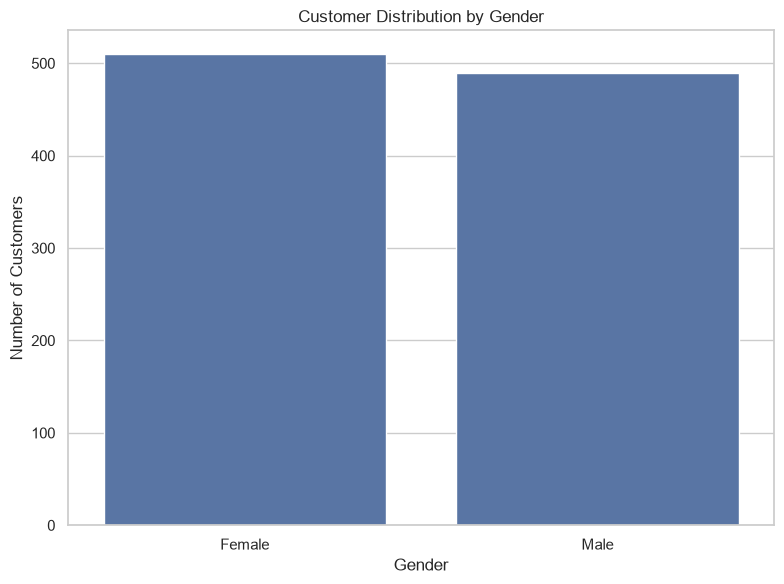

In [40]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x=gender_counts.index,
    y=gender_counts.values
)

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig("../images/gender_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

### Observation

The gender distribution is relatively balanced, although female customers represent a slightly larger share of the dataset than male customers. There are approximately 510 female customers compared with 490 male customers. The small difference suggests that the business has a fairly balanced customer base and does not appear to be overwhelmingly concentrated in one gender.

## Product Category Sales Analysis

The dataset does not contain individual product names; therefore, product performance is analyzed at the product-category level using total quantity sold.
"The selected dataset provides product categories rather than individual product names. Therefore, product-level performance was analyzed using product categories."

In [41]:
# Calculate total quantity sold for each product category
category_quantity = (
    df.groupby("Product Category")["Quantity"]
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

category_quantity

,Product Category,Quantity
0,Clothing,894
1,Electronics,849
2,Beauty,771


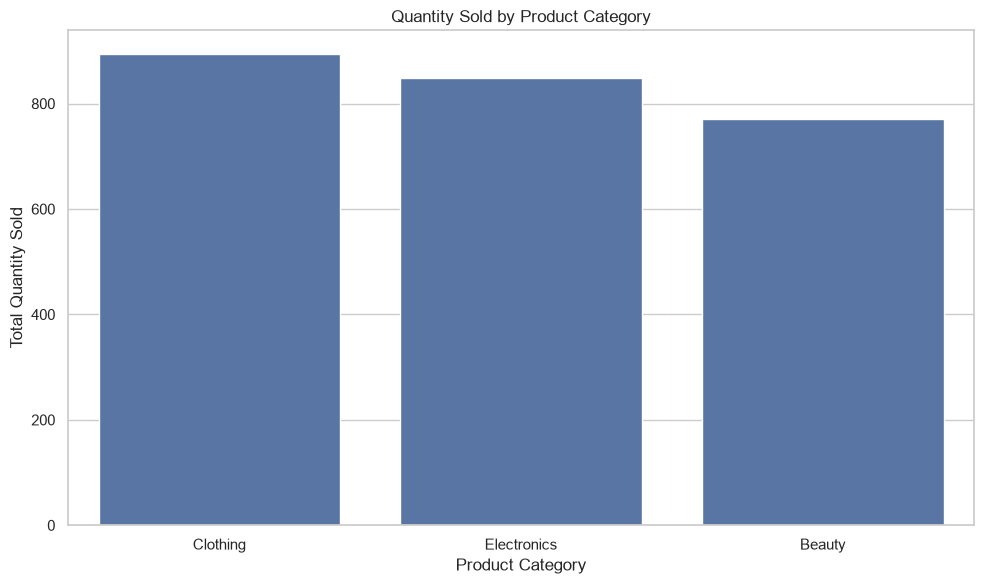

In [42]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_quantity,
    x="Product Category",
    y="Quantity"
)

plt.title("Quantity Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")

plt.tight_layout()

plt.savefig(
    "../images/quantity_by_product_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

Clothing has the highest total quantity sold among the three product categories, followed by Electronics and Beauty. This indicates that Clothing has the greatest sales volume in terms of the number of items purchased. However, quantity sold alone does not indicate which category generates the most revenue, so the results should be considered together with the revenue-by-category analysis.

### Revenue by Product Category

Revenue is aggregated by product category to identify which categories generate the greatest amount of sales.

In [43]:
category_revenue = (
    df.groupby("Product Category")["Total Amount"]
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

category_revenue

,Product Category,Total Amount
0,Electronics,156905
1,Clothing,155580
2,Beauty,143515


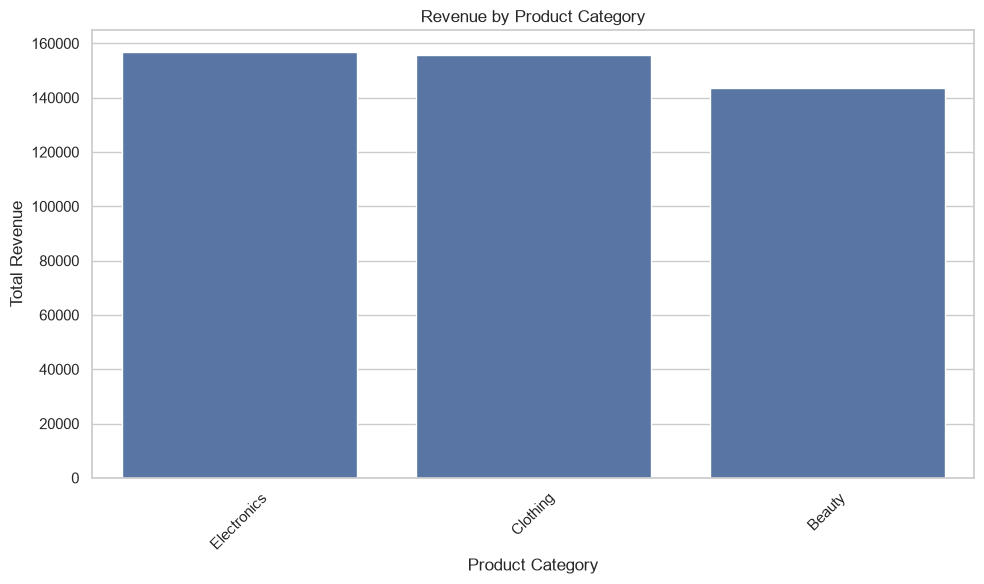

In [44]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_revenue,
    x="Product Category",
    y="Total Amount"
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig("../images/revenue_by_category.png", dpi=300, bbox_inches="tight")

plt.show()

### Observation

Electronics generates the highest total revenue at approximately $156,905, followed very closely by Clothing at approximately $155,580. Beauty generates the lowest revenue at approximately $143,515. An important insight is that Clothing has the highest quantity sold, while Electronics generates the highest revenue. This indicates that sales volume and revenue contribution are not necessarily the same and that product pricing also influences revenue performance.

## Correlation Analysis

A correlation matrix is used to examine relationships between numerical variables. Correlation values range from -1 to +1, where values closer to +1 indicate a strong positive relationship and values closer to -1 indicate a strong negative relationship.

In [45]:
correlation_matrix = df.select_dtypes(include=np.number).corr()

correlation_matrix

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
Transaction ID,1.000000,0.065191,-0.026623,-0.060837,-0.075034
Age,0.065191,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.026623,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.060837,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.075034,-0.060568,0.373707,0.851925,1.000000


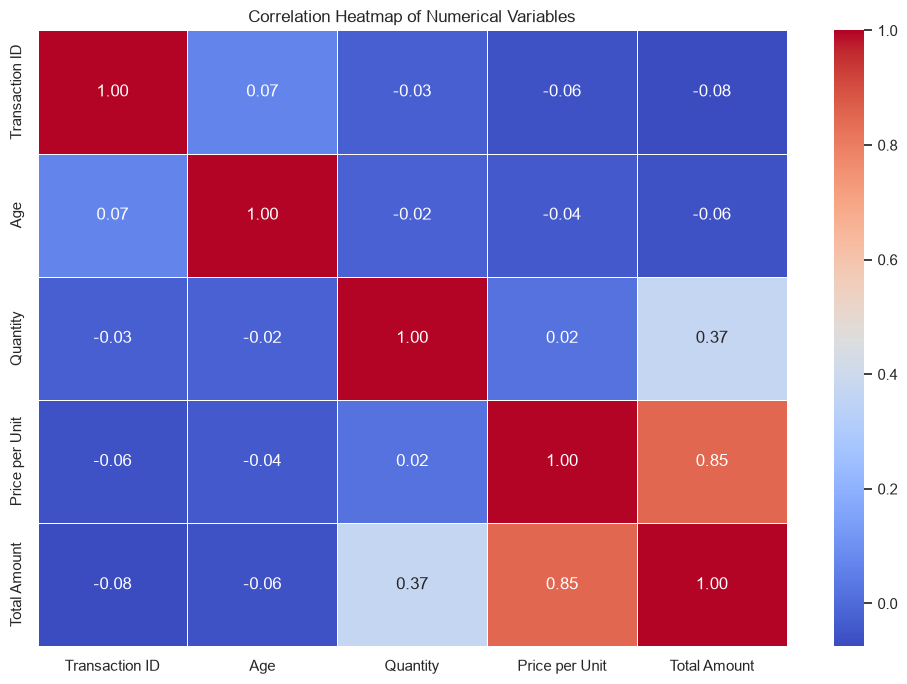

In [46]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")

plt.tight_layout()

plt.savefig("../images/correlation_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

### Observation

The strongest relationship in the correlation matrix is between Price per Unit and Total Amount, with a strong positive correlation of approximately 0.85. Quantity also has a positive relationship with Total Amount, although it is considerably weaker at approximately 0.37. Age has almost no linear relationship with Total Amount, with a correlation of approximately -0.06. These results indicate that transaction value is much more strongly associated with unit price than with customer age.

## Additional Business Insight

### Average Transaction Value by Age Group

Customer counts alone do not show which demographic groups generate higher-value purchases. To identify a less obvious business insight, average transaction value is compared across customer age groups.

In [47]:
age_spending = (
    df.groupby("Age Group", observed=True)["Total Amount"]
      .mean()
      .reset_index()
)

age_spending

,Age Group,Total Amount
0,18-25,500.295858
1,26-35,480.390244
2,36-45,454.801980
3,46-55,439.694323
4,56-65,412.358974


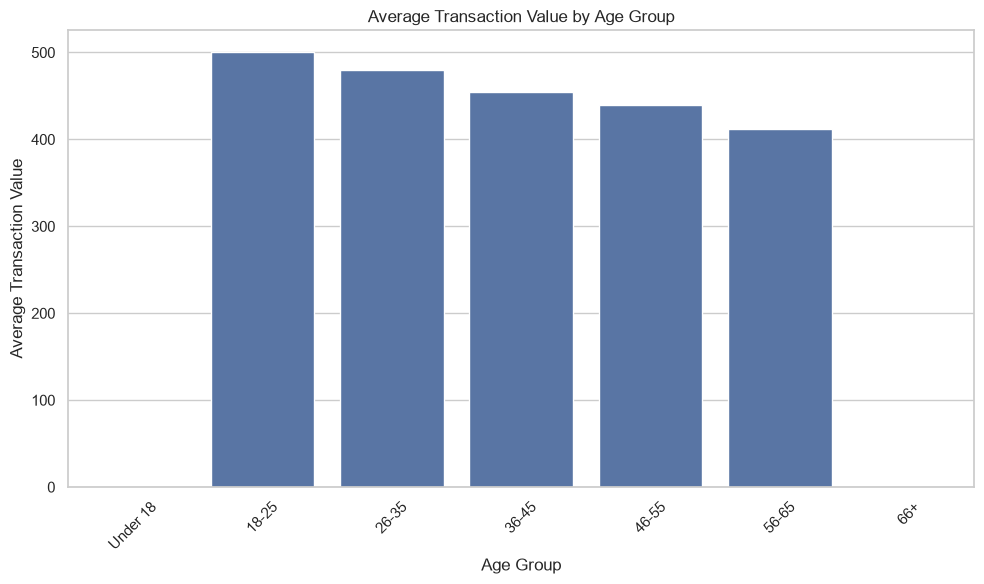

In [48]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_spending,
    x="Age Group",
    y="Total Amount"
)

plt.title("Average Transaction Value by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Transaction Value")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig("../images/average_transaction_by_age.png", dpi=300, bbox_inches="tight")

plt.show()

### Observation

The average transaction value decreases progressively across the observed age groups. Customers aged 18–25 have the highest average transaction value, at approximately $500, while customers aged 56–65 have the lowest average at approximately $410. This reveals an important difference between customer volume and spending value: although the 46–55 group is the largest customer segment, the younger 18–25 group has the highest average transaction value.

### Revenue by Gender

Revenue is compared across genders to determine whether customer groups differ in their overall contribution to sales.

In [49]:
gender_revenue = (
    df.groupby("Gender")["Total Amount"]
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)

gender_revenue

,Gender,Total Amount
0,Female,232840
1,Male,223160


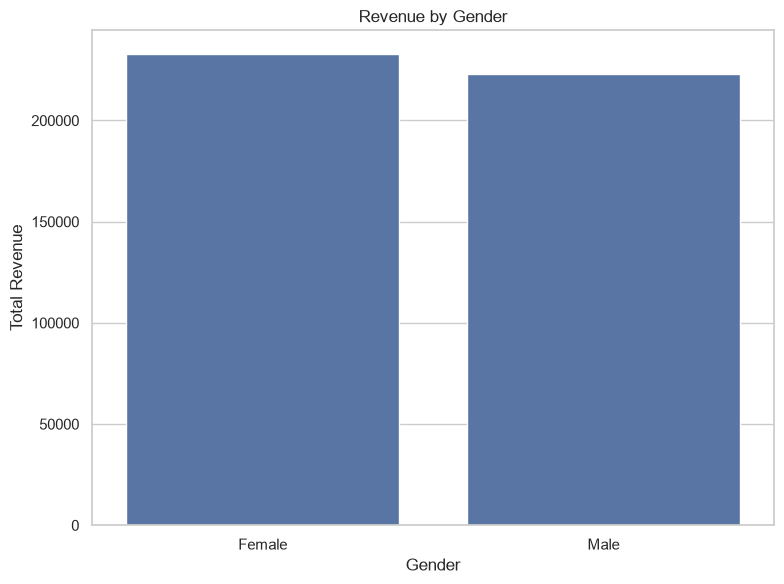

In [50]:
plt.figure(figsize=(8, 6))

sns.barplot(
    data=gender_revenue,
    x="Gender",
    y="Total Amount"
)

plt.title("Revenue by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Revenue")

plt.tight_layout()

plt.savefig("../images/revenue_by_gender.png", dpi=300, bbox_inches="tight")

plt.show()

### Observation

Female customers generate slightly more total revenue than male customers, with approximately $232,840 compared with $223,160. The difference is relatively small, indicating that revenue contribution is fairly balanced between the two groups. Therefore, marketing decisions should not rely exclusively on gender and should also consider age groups, product categories, and spending behaviour.

# Key Findings

The exploratory analysis produced the following key findings:

1. **Monthly sales fluctuate significantly.** May 2023 recorded the highest monthly sales at approximately $53,150, while September recorded the lowest sales among the complete 2023 months at approximately $23,620.

2. **Quarterly performance varies across the year.** Q4 2023 was the strongest complete quarter, while Q3 2023 recorded the lowest sales among the complete quarters.

3. **The customer base is concentrated between ages 18 and 65.** The 46–55 age group represents the largest customer segment, while there are no customers under 18 or above 65 in the dataset.

4. **The gender distribution is relatively balanced.** Female customers represent approximately 510 records compared with approximately 490 male records.

5. **Clothing has the highest quantity sold.** Clothing leads the product categories in terms of sales volume, followed by Electronics and Beauty.

6. **Electronics generates the highest revenue.** Electronics produces approximately $156,905 in revenue, slightly higher than Clothing at approximately $155,580 and Beauty at approximately $143,515.

7. **Revenue is strongly related to unit price.** The correlation between Price per Unit and Total Amount is approximately 0.85, while the correlation between Quantity and Total Amount is weaker at approximately 0.37.

8. **Age has very little linear relationship with transaction value.** The correlation between Age and Total Amount is approximately -0.06.

9. **Younger customers show higher average transaction values.** The 18–25 age group has the highest average transaction value, while the 56–65 group has a lower average transaction value.

10. **Female customers contribute slightly more total revenue than male customers.** Female revenue is approximately $232,840 compared with approximately $223,160 for male customers.

11. **Sales volume and revenue are not identical measures of performance.** Clothing sells the highest quantity, while Electronics generates the highest revenue, demonstrating the effect of pricing on revenue generation.

# Business Recommendations

Based on the findings from the exploratory data analysis, the following actionable recommendations are proposed:

### 1. Plan inventory according to monthly and quarterly demand

The business should use historical sales patterns when planning inventory and promotional campaigns. In particular, the strong performance observed in May and Q4 suggests that sufficient inventory should be available before periods of higher demand.

### 2. Prioritize Electronics while maintaining Clothing inventory

Electronics generates the highest revenue, while Clothing has the highest quantity sold. The business should therefore maintain strong availability in both categories, while monitoring Electronics as an important revenue-generating category.

### 3. Investigate the lower performance of Beauty

Beauty generates less revenue than Electronics and Clothing. The business should investigate whether pricing, product selection, promotions, or customer demand is responsible for the lower revenue contribution and consider targeted promotions to improve performance.

### 4. Target high-value younger customers

The 18–25 age group has the highest average transaction value. The business could develop targeted digital promotions, loyalty offers, and product bundles aimed at this group to encourage repeat purchases and increase customer lifetime value.

### 5. Develop campaigns for the largest customer segment

The 46–55 age group represents the largest customer segment. Marketing campaigns should therefore include offers and products relevant to this demographic while avoiding a one-size-fits-all strategy.

### 6. Use pricing strategically

The strong 0.85 correlation between Price per Unit and Total Amount indicates that unit price is strongly associated with transaction value. The business should evaluate pricing and product mix carefully to increase revenue without negatively affecting demand.

### 7. Avoid relying on gender alone for marketing decisions

Although female customers generate slightly more revenue than male customers, the difference is relatively small. Marketing decisions should therefore combine gender with age, product category, transaction value, and purchasing behaviour.

# Conclusion

The exploratory data analysis provided a detailed overview of the retail sales dataset and revealed important patterns in sales performance, customer demographics, product categories, and transaction behaviour.

Sales performance varies considerably over time, with May 2023 recording the highest monthly sales and Q4 2023 representing the strongest complete quarter. The customer base is primarily composed of adults between 18 and 65, with the 46–55 age group representing the largest segment.

The product analysis showed that Clothing has the highest sales volume, while Electronics generates the highest revenue. This difference demonstrates that sales quantity and revenue should be evaluated together rather than independently.

The correlation analysis showed a strong positive relationship between Price per Unit and Total Amount, while Age had very little linear relationship with transaction value. The additional age-group analysis also showed that younger customers, particularly those aged 18–25, have higher average transaction values despite not being the largest customer segment.

Overall, the findings can help the business improve inventory planning, pricing decisions, customer targeting, product promotion, and marketing strategies. The recommendations developed from the analysis provide practical ways to use the available sales data for more informed business decision-making.